In [1]:
import spacy
import pandas as pd

In [2]:
nlp = spacy.load("en_core_web_sm")

In [3]:
# we have removed punctuation, lowercased but left in stop words
emma_ja = "emma woodhouse handsome clever and rich with a comfortable home and happy disposition seemed to unite some of the best blessings of existence and had lived nearly twentyone years in the world with very little to distress or vex her she was the youngest of the two daughters of a most affectionate indulgent father and had in consequence of her sisters marriage been mistress of his house from a very early period her mother had died too long ago for her to have more than an indistinct remembrance of her caresses and her place had been supplied by an excellent woman as governess who had fallen little short of a mother in affection sixteen years had miss taylor been in mr woodhouses family less as a governess than a friend very fond of both daughters but particularly of emma between them it was more the intimacy of sisters even before miss taylor had ceased to hold the nominal office of governess the mildness of her temper had hardly allowed her to impose any restraint and the shadow of authority being now long passed away they had been living together as friend and friend very mutually attached and emma doing just what she liked highly esteeming miss taylors judgment but directed chiefly by her own"
print(emma_ja)

emma woodhouse handsome clever and rich with a comfortable home and happy disposition seemed to unite some of the best blessings of existence and had lived nearly twentyone years in the world with very little to distress or vex her she was the youngest of the two daughters of a most affectionate indulgent father and had in consequence of her sisters marriage been mistress of his house from a very early period her mother had died too long ago for her to have more than an indistinct remembrance of her caresses and her place had been supplied by an excellent woman as governess who had fallen little short of a mother in affection sixteen years had miss taylor been in mr woodhouses family less as a governess than a friend very fond of both daughters but particularly of emma between them it was more the intimacy of sisters even before miss taylor had ceased to hold the nominal office of governess the mildness of her temper had hardly allowed her to impose any restraint and the shadow of auth

In [4]:
# create a spacy doc from our text - this will generate tokens and their assosciated pos tags
spacy_doc =nlp(emma_ja)

In [5]:
type(spacy_doc)

spacy.tokens.doc.Doc

In [6]:
pos_df =pd.DataFrame(columns=['token','pos_tag'])

for token in spacy_doc:
    print(token.text)
    print(token.pos_)

emma
PROPN
woodhouse
PROPN
handsome
ADJ
clever
ADJ
and
CCONJ
rich
ADJ
with
ADP
a
DET
comfortable
ADJ
home
NOUN
and
CCONJ
happy
ADJ
disposition
NOUN
seemed
VERB
to
PART
unite
VERB
some
PRON
of
ADP
the
DET
best
ADJ
blessings
NOUN
of
ADP
existence
NOUN
and
CCONJ
had
AUX
lived
VERB
nearly
ADV
twentyone
NUM
years
NOUN
in
ADP
the
DET
world
NOUN
with
ADP
very
ADV
little
ADJ
to
PART
distress
NOUN
or
CCONJ
vex
NOUN
her
PRON
she
PRON
was
AUX
the
DET
youngest
ADJ
of
ADP
the
DET
two
NUM
daughters
NOUN
of
ADP
a
DET
most
ADV
affectionate
ADJ
indulgent
ADJ
father
NOUN
and
CCONJ
had
AUX
in
ADP
consequence
NOUN
of
ADP
her
PRON
sisters
NOUN
marriage
NOUN
been
AUX
mistress
NOUN
of
ADP
his
PRON
house
NOUN
from
ADP
a
DET
very
ADV
early
ADJ
period
NOUN
her
PRON
mother
NOUN
had
AUX
died
VERB
too
ADV
long
ADV
ago
ADV
for
SCONJ
her
PRON
to
PART
have
VERB
more
ADJ
than
ADP
an
DET
indistinct
ADJ
remembrance
NOUN
of
ADP
her
PRON
caresses
NOUN
and
CCONJ
her
PRON
place
NOUN
had
AUX
been
AUX
supplied
VERB
by
ADP
an


In [7]:
for token in spacy_doc:
    pos_df = pd.concat([pos_df,
                        pd.DataFrame.from_records([{'token':token.text,
                                                   'pos_tag':token.pos_}])]
                      ,ignore_index=True)

In [8]:
pos_df.head(15)

,token,pos_tag
0,emma,PROPN
1,woodhouse,PROPN
2,handsome,ADJ
3,clever,ADJ
4,and,CCONJ
5,rich,ADJ
6,with,ADP
7,a,DET
8,comfortable,ADJ
9,home,NOUN



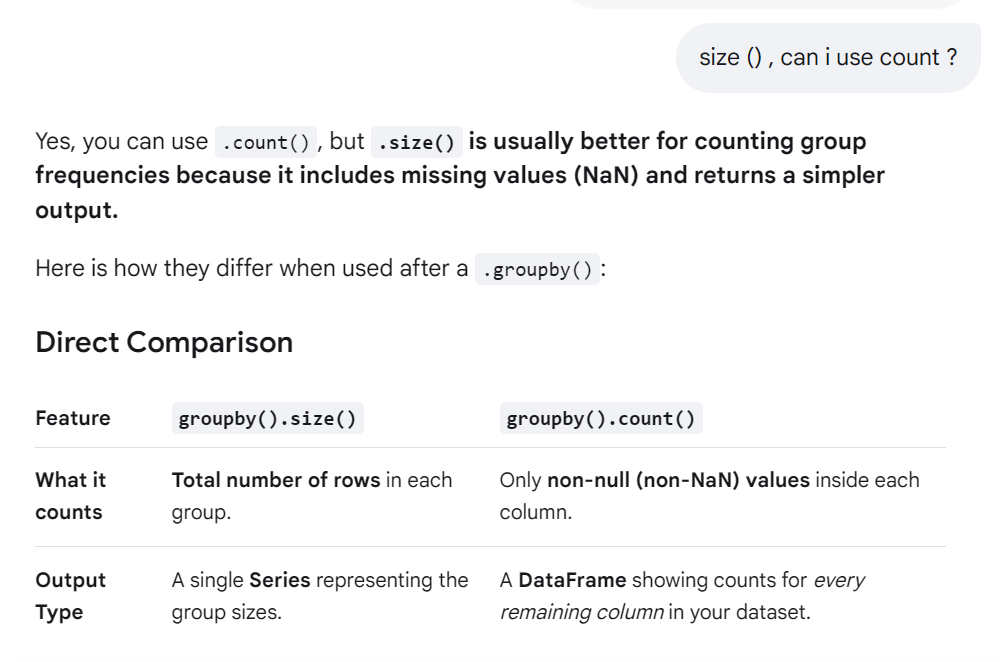

In [10]:
# find the most common token and their associated pos tag 
pos_df_count =pos_df.groupby(["token","pos_tag"]).size().reset_index(name="counts").sort_values(by="counts", ascending=False)
pos_df_count.head(10)

,token,pos_tag,counts
88,of,ADP,14
49,had,AUX,9
54,her,PRON,9
111,the,DET,8
6,and,CCONJ,8
0,a,DET,6
114,to,PART,5
61,in,ADP,4
13,been,AUX,4
120,very,ADV,4


In [11]:
# how many different words fall under each pos tag
# To quickly see the most common POS tags overall:
pos_df["pos_tag"].value_counts()

pos_tag
NOUN     44
ADP      28
ADV      22
ADJ      19
VERB     19
DET      18
PRON     18
AUX      16
CCONJ    11
PROPN     8
PART      5
NUM       3
SCONJ     3
Name: count, dtype: int64

In [12]:
pos_df_count.groupby(["pos_tag"])["token"].count().sort_values(ascending=False)

pos_tag
NOUN     35
VERB     19
ADJ      18
ADV      18
PRON      9
ADP       8
PROPN     6
DET       5
AUX       4
CCONJ     3
NUM       3
SCONJ     3
PART      1
Name: token, dtype: int64

In [13]:
nouns = pos_df_count[pos_df_count.pos_tag=="NOUN"][:10]
nouns

,token,pos_tag,counts
48,governess,NOUN,3
46,friend,NOUN,3
130,years,NOUN,2
35,emma,NOUN,2
28,daughters,NOUN,2
103,sisters,NOUN,2
82,mother,NOUN,2
89,office,NOUN,1
78,mistress,NOUN,1
75,mildness,NOUN,1


In [14]:
import spacy
from spacy import displacy 
from spacy import tokenizer
from IPython.display import HTML , display
import re

In [15]:
nlp =spacy.load("en_core_web_sm")